# 1.문제정의
- 뇌졸중 환자의 건강 및 생활습관 데이터를 기반으로 새로운 환자가 뇌졸중에 걸릴 위험이 있는지분석 하는 모델을 만들자.
- 의사결정트리 모델을 활용하여 분류 및 시각화 

# 2. 데이터 수집
- 'stroke_data.csv' 불러오기

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [2]:
data = pd.read_csv('data/stroke_data.csv')
data

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,77,Female,13.0,0,0,No,children,Rural,85.81,18.6,Unknown,0
1,84,Male,55.0,0,0,Yes,Private,Urban,89.17,31.5,never smoked,0
2,91,Female,42.0,0,0,No,Private,Urban,98.53,18.5,never smoked,0
3,99,Female,31.0,0,0,No,Private,Urban,108.89,52.3,Unknown,0
4,129,Female,24.0,0,0,No,Private,Urban,97.55,26.2,never smoked,0
...,...,...,...,...,...,...,...,...,...,...,...,...
4904,72911,Female,57.0,1,0,Yes,Private,Rural,129.54,60.9,smokes,0
4905,72914,Female,19.0,0,0,No,Private,Urban,90.57,24.2,Unknown,0
4906,72915,Female,45.0,0,0,Yes,Private,Urban,172.33,45.3,formerly smoked,0
4907,72918,Female,53.0,1,0,Yes,Private,Urban,62.55,30.3,Unknown,1


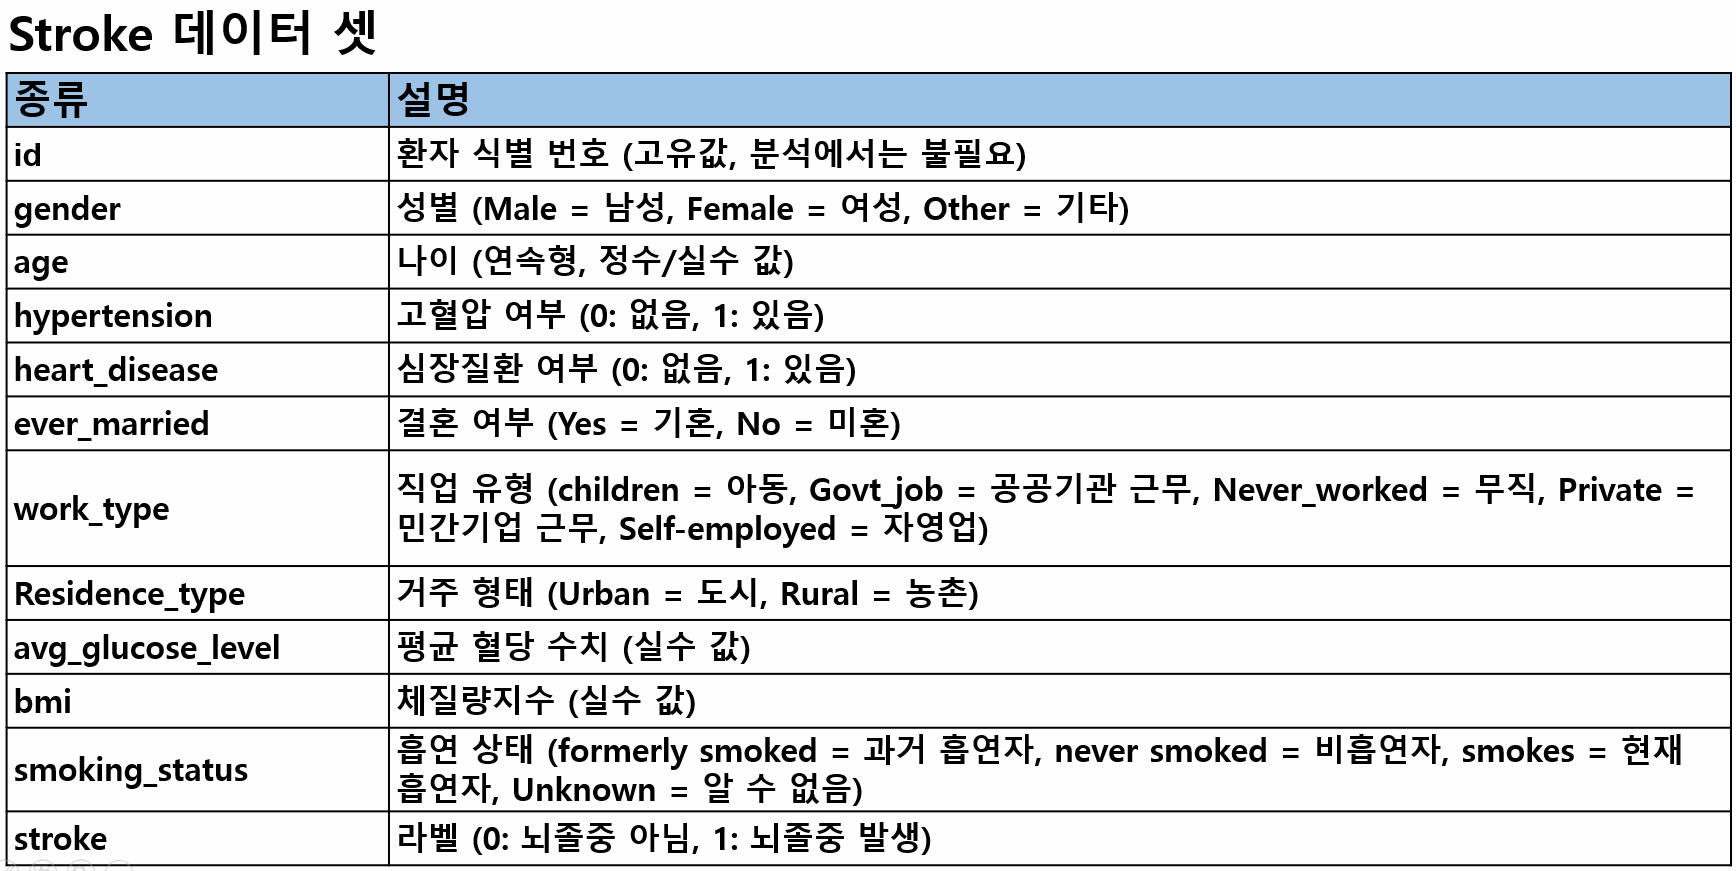

# 3. 데이터 전처리 & 4. EDA(탐색적 데이터 분석)

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4909 entries, 0 to 4908
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4909 non-null   int64  
 1   gender             4909 non-null   object 
 2   age                4909 non-null   float64
 3   hypertension       4909 non-null   int64  
 4   heart_disease      4909 non-null   int64  
 5   ever_married       4909 non-null   object 
 6   work_type          4909 non-null   object 
 7   Residence_type     4909 non-null   object 
 8   avg_glucose_level  4909 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     4909 non-null   object 
 11  stroke             4909 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 460.3+ KB


In [4]:
# 기술 통계 분석
data.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,4909.000000,4909.000000,4909.000000,4909.000000,4909.000000,4909.000000,4909.000000
mean,37064.313506,42.865374,0.091872,0.049501,105.305150,28.893237,0.042575
std,20995.098457,22.555115,0.288875,0.216934,44.424341,7.854067,0.201917
min,77.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,18605.000000,25.000000,0.000000,0.000000,77.070000,23.500000,0.000000
50%,37608.000000,44.000000,0.000000,0.000000,91.680000,28.100000,0.000000
75%,55220.000000,60.000000,0.000000,0.000000,113.570000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [5]:
# 기술 통계 분석
data.describe(include = 'object')

,gender,ever_married,work_type,Residence_type,smoking_status
count,4909,4909,4909,4909,4909
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2897,3204,2811,2490,1852


In [6]:
# 인코딩
# 문자형 데이터 -> 수치형 데이터
# Label_Encoding : 값에 우선순위가 판단될 경우(map(딕셔너리))
# One_Hot_Encodig : 값에 우선순위가 없다고 판단될 경우(pd.get_dummies(데이터, dtype = 'int'))

In [7]:
#data_Encodig
data['smoking_status'].unique()

array(['Unknown', 'never smoked', 'smokes', 'formerly smoked'],
      dtype=object)

In [8]:
#data[컬럼].map[{값 할당}]
if data['smoking_stauts'].dtype == 'o':
    data['smoking_status'] = data['smoking_status'].map({'Unknown':0, 'never smoked':1,
                                'formerly smoked':2, 'smokes':3})

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,77,Female,13.0,0,0,No,children,Rural,85.81,18.6,0,0
1,84,Male,55.0,0,0,Yes,Private,Urban,89.17,31.5,1,0
2,91,Female,42.0,0,0,No,Private,Urban,98.53,18.5,1,0
3,99,Female,31.0,0,0,No,Private,Urban,108.89,52.3,0,0
4,129,Female,24.0,0,0,No,Private,Urban,97.55,26.2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
4904,72911,Female,57.0,1,0,Yes,Private,Rural,129.54,60.9,3,0
4905,72914,Female,19.0,0,0,No,Private,Urban,90.57,24.2,0,0
4906,72915,Female,45.0,0,0,Yes,Private,Urban,172.33,45.3,2,0
4907,72918,Female,53.0,1,0,Yes,Private,Urban,62.55,30.3,0,1


In [9]:
data['smoking_status']

0       0
1       1
2       1
3       0
4       1
       ..
4904    3
4905    0
4906    2
4907    0
4908    0
Name: smoking_status, Length: 4909, dtype: int64

In [10]:
#One_Hot_Encoding
data_enc = pd.get_dummies(data, dtype='int')
data_enc

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban
0,77,13.0,0,0,85.81,18.6,0,0,1,0,0,1,0,0,0,0,0,1,1,0
1,84,55.0,0,0,89.17,31.5,1,0,0,1,0,0,1,0,0,1,0,0,0,1
2,91,42.0,0,0,98.53,18.5,1,0,1,0,0,1,0,0,0,1,0,0,0,1
3,99,31.0,0,0,108.89,52.3,0,0,1,0,0,1,0,0,0,1,0,0,0,1
4,129,24.0,0,0,97.55,26.2,1,0,1,0,0,1,0,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4904,72911,57.0,1,0,129.54,60.9,3,0,1,0,0,0,1,0,0,1,0,0,1,0
4905,72914,19.0,0,0,90.57,24.2,0,0,1,0,0,1,0,0,0,1,0,0,0,1
4906,72915,45.0,0,0,172.33,45.3,2,0,1,0,0,0,1,0,0,1,0,0,0,1
4907,72918,53.0,1,0,62.55,30.3,0,1,1,0,0,0,1,0,0,1,0,0,0,1


In [12]:
# 데이터의 상관관계 분석(corr())
# correLation coefficient(상관계수) : 특성들 간에 비례, 반비례 관계를 숫자로 표현
data_enc.corr()
# -1 ~ 1 사이의 값을 가짐
# 1에 가까울수록 완전한 비례관계
# -1에 가까울수록 완전한 반비례관계
# 0에 가까울수록 상관관계가 없음

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban
id,1.000000,0.008984,0.001147,0.004016,0.006409,0.003084,0.021877,0.004839,-0.006695,0.006319,0.012981,-0.016841,0.016841,0.004272,0.003868,0.026498,-0.021856,-0.019873,-0.004978,0.004978
age,0.008984,1.000000,0.274425,0.257123,0.235838,0.333398,0.317886,0.232331,0.030457,-0.030149,-0.010674,-0.680782,0.680782,0.133593,-0.079384,0.120021,0.327347,-0.634937,-0.010948,0.010948
hypertension,0.001147,0.274425,1.000000,0.115991,0.180543,0.167811,0.106902,0.142515,-0.021730,0.021863,-0.004540,-0.162406,0.162406,0.019232,-0.021341,-0.004637,0.111794,-0.126561,0.001074,-0.001074
heart_disease,0.004016,0.257123,0.115991,1.000000,0.154525,0.041357,0.093732,0.137938,-0.082882,0.082983,-0.003257,-0.111245,0.111245,0.005095,-0.015312,-0.000279,0.081484,-0.088072,0.002362,-0.002362
avg_glucose_level,0.006409,0.235838,0.180543,0.154525,1.000000,0.175502,0.081368,0.138936,-0.053358,0.053008,0.012219,-0.151377,0.151377,0.017723,-0.013991,0.009273,0.069051,-0.101182,0.007617,-0.007617
bmi,0.003084,0.333398,0.167811,0.041357,0.175502,1.000000,0.222564,0.042374,0.026360,-0.026020,-0.011802,-0.341695,0.341695,0.079584,-0.028602,0.208029,0.072701,-0.448674,0.000122,-0.000122
smoking_status,0.021877,0.317886,0.106902,0.093732,0.081368,0.222564,1.000000,0.069839,0.003389,-0.003727,0.011610,-0.291171,0.291171,0.077310,-0.034943,0.174797,0.081051,-0.406232,-0.026714,0.026714
stroke,0.004839,0.232331,0.142515,0.137938,0.138936,0.042374,0.069839,1.000000,-0.006851,0.006939,-0.003010,-0.105089,0.105089,0.003553,-0.014149,0.014934,0.055356,-0.080971,-0.006031,0.006031
gender_Female,-0.006695,0.030457,-0.021730,-0.082882,-0.053358,0.026360,0.003389,-0.006851,1.000000,-0.999579,-0.017128,-0.036703,0.036703,0.015123,-0.012297,0.038611,0.022312,-0.091619,-0.004598,0.004598
gender_Male,0.006319,-0.030149,0.021863,0.082983,0.053008,-0.026020,-0.003727,0.006939,-0.999579,1.000000,-0.011891,0.036138,-0.036138,-0.014965,0.012326,-0.038972,-0.022134,0.091791,0.004178,-0.004178


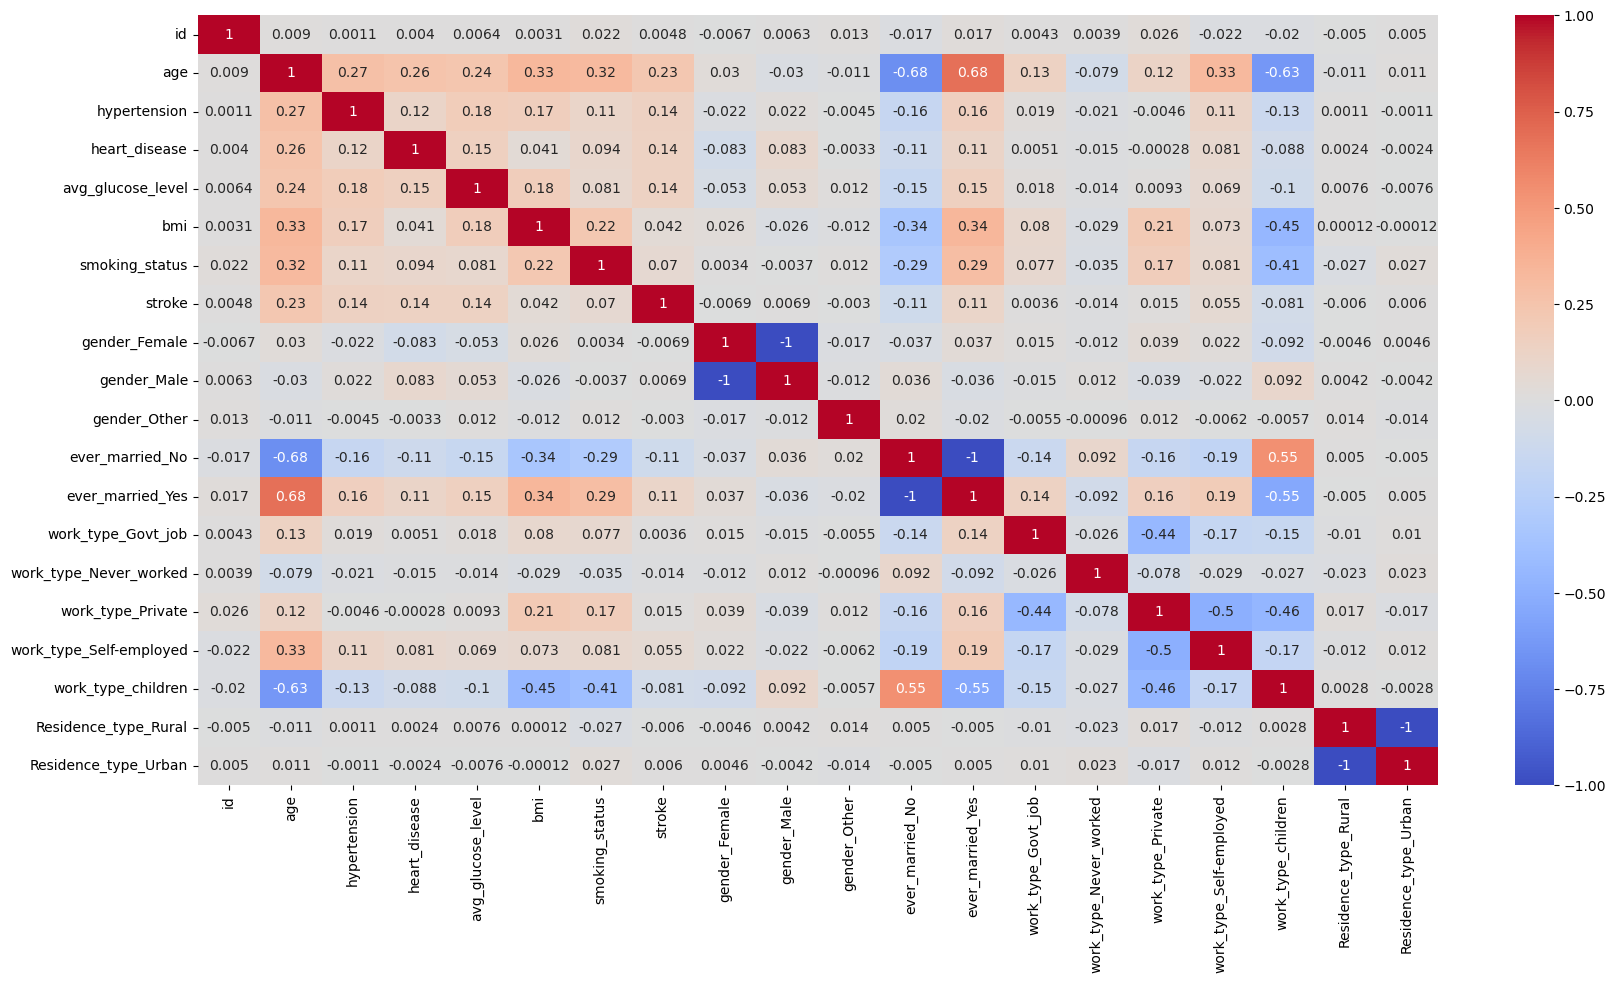

In [15]:
# 히트맵 : 숫자값을 색의 진하기로 표현한 시각화 그래프
# 도화지 만들기
plt.figure(figsize=(20,10))
# 차트 그리기
# seaborn : matplotlib을 기반으로 좀 더 편하게 시각화하는 도구
import seaborn as sns
# 히트맵 : sns.heatmap(데이터, annot = True(수치값 표시), cmap = ''(색상테마))
sns.heatmap(data_enc.corr(), annot=True, cmap='coolwarm')


# 시각화 및 초기화
plt.show()

In [18]:
# 데이터 분리
# 문제 데이터 / 정답 데이터 분리
# 문제 데이터 : stroke 컬럼을 제외한 모든 컬럼(특성)
# 정답 데이터 : stroke

# data_enc.drop(제거하고싶은컬럼, axis=1, or 'column')
X = data_enc.drop('stroke', axis=1)
y = data_enc['stroke']

In [22]:
from sklearn.model_selection import train_test_split

In [24]:
# 훈련/테스트 데이터
# 데이터 비율 7 : 3 랜덤스테이트 2026, 클래스 비율 동일
X_train, X_test, y_train, y_test = train_test_split(
    X,y, #원본데이터(문제, 정답)
    test_size = 0.3, # 나누고 싶은 테스트 데이터의 비율
    random_state = 2026, # 랜덤 데이터의 규칙을 고정
    stratify = y # 결과값이 범주형(분류모델)일 때, 훈련/테스트 클래스 비율 동일
)


In [26]:
print('훈련 : ', X_train.shape, y_train.shape)
print('테스트 : ', X_test.shape, y_test.shape)

훈련 :  (3436, 19) (3436,)
테스트 :  (1473, 19) (1473,)


# 5. 모델 선택
- 의사결정트리 모델 불러오기

In [27]:
# 모델 불러오기
from sklearn.tree import DecisionTreeClassifier

In [28]:
# 모델 객체 생성
tree = DecisionTreeClassifier()

# 6. 모델 학습

In [29]:
tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


# 7. 모델 평가

In [31]:
tree.score(X_test, y_test)

print('훈련 : ', tree.score(X_train, y_train))
print('테스트 : ',tree.score(X_test, y_test))

훈련 :  1.0
테스트 :  0.911744738628649


In [32]:
# 교차검증 도구 불러오기
from sklearn.model_selection import cross_val_score

In [34]:
# k-fold 교차 검증
# cross_val_score(모델, 훈련데이터, cv = 교차검증횟수)
cv = cross_val_score(tree, X_train, y_train, cv = 5)

In [35]:
# 다섯개 검증 모델 성능의 평균 구하기
cv.mean()

np.float64(0.915892742290376)

# 추가 실습

## 트리모델 시각화

In [37]:
from sklearn.tree import plot_tree

In [41]:
#matplotlib 한글 설정
plt.rc('font', family = 'Malgun Gothic') # 폰트 지정
plt.rc('axes', unicode_minus=False) # 마이너스 기호 표시

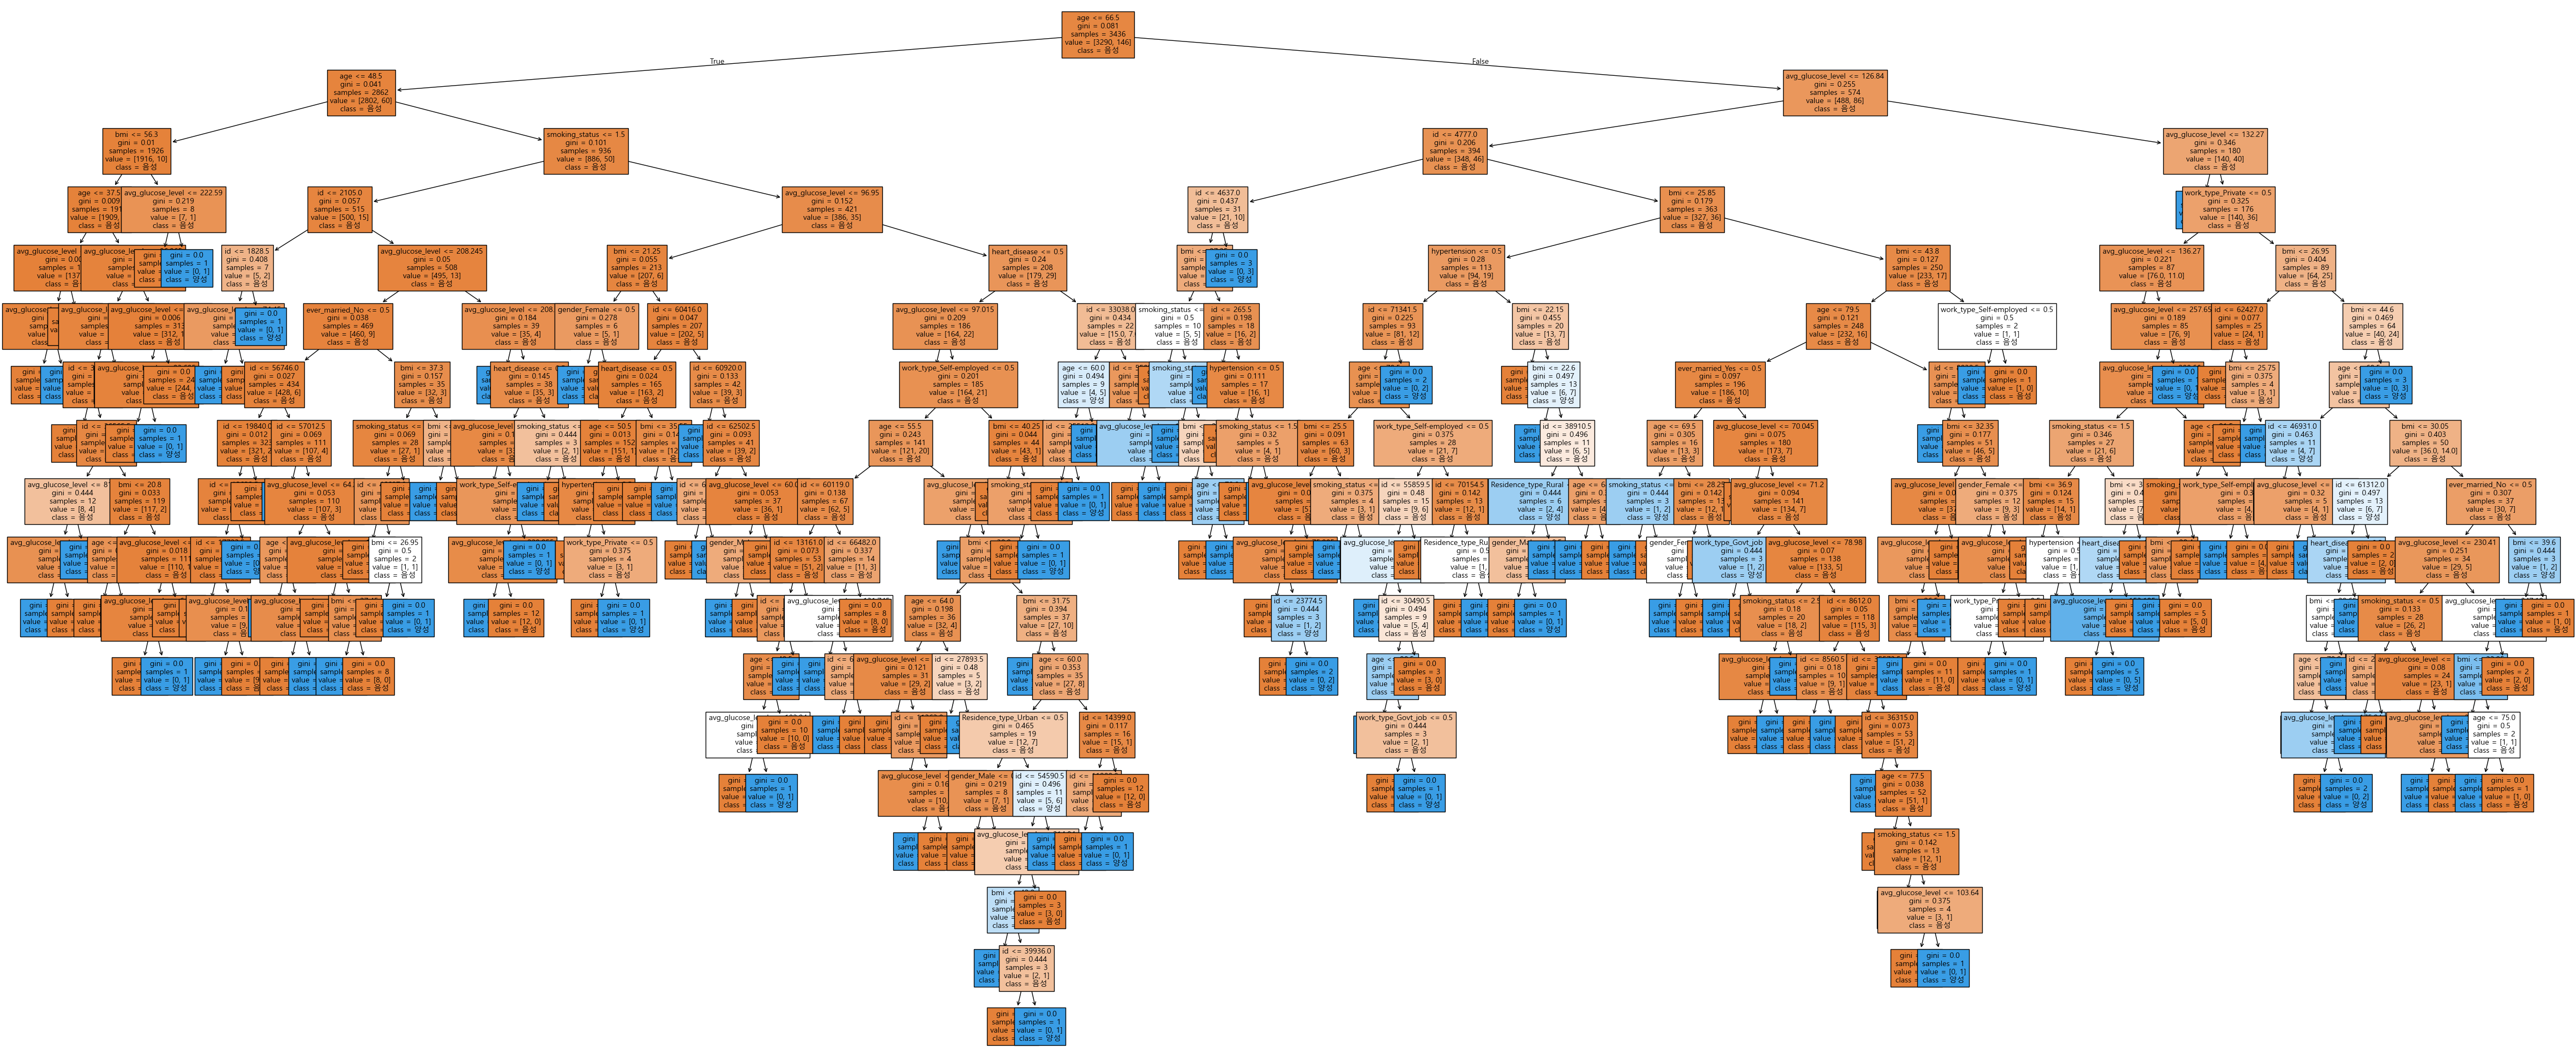

In [43]:
# 트리 데이터 시각화
# 도화지
plt.figure(figsize=(60,25))

# 차트 그리기plot_tree(모델, feature_names = X_train.columns(미설정시 X[0]), 
#                                            class_names = ['음성', '양성']), filled = True(클래스 비율 시각화), fontsize=글자크기)
plot_tree(tree, feature_names = X_train.columns, 
                                class_names = ['음성', '양성'], filled = True, fontsize=10)

#이미지 저장
# plt.savefig('파일 경로/ 이름', dpi = 해상도, bbox_inches='여백크기')
plt.savefig('./data/tree.png', dpi = 300, bbox_inches='tight')

# 시각화 및 초기화
plt.show()

## 특성 중요도 확인
- 트리모델이 학습하면서 각 특성이 얼마나 의사결정에 기여했는지를 수치화

In [45]:
# 특성 중요도 확인
fi = tree.feature_importances_

In [47]:
# 특성 중요도 데이터프레임화
fi_df = pd.DataFrame(fi, index=X_train.columns, columns=['특성중요도'])

In [49]:
# 특성 중요도 내림차순 정렬
fi_df.sort_values(by='특성중요도', ascending = False)

# 혈당수치와 bmi가 뇌졸중 분류할 때 의사결정하는데 있어서 가장 많은 기여를 했다.

,특성중요도
avg_glucose_level,0.267186
id,0.226246
bmi,0.158428
age,0.152801
smoking_status,0.056545
work_type_Self-employed,0.023563
gender_Female,0.019195
heart_disease,0.018908
work_type_Private,0.016450
gender_Male,0.016393


## 하이퍼 파라미터 조정
- max_depth
- mii=n_left_nodes
- min_samples_split

In [51]:
# 모델 객체 생성(max_depth)
tree_md5 = DecisionTreeClassifier(max_depth=5)

In [52]:
# 모델 학습
tree_md5.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [53]:
# 모델 평가
print('훈련 : ', tree_md5.score(X_train, y_train))
print('테스트 : ',tree_md5.score(X_test, y_test))

훈련 :  0.960710128055879
테스트 :  0.9531568228105907


In [58]:
# 교차 검증
cv_md5 = cross_val_score(tree_md5, X_train, y_train, cv = 5).mean()
cv_md5

np.float64(0.9508141227446598)

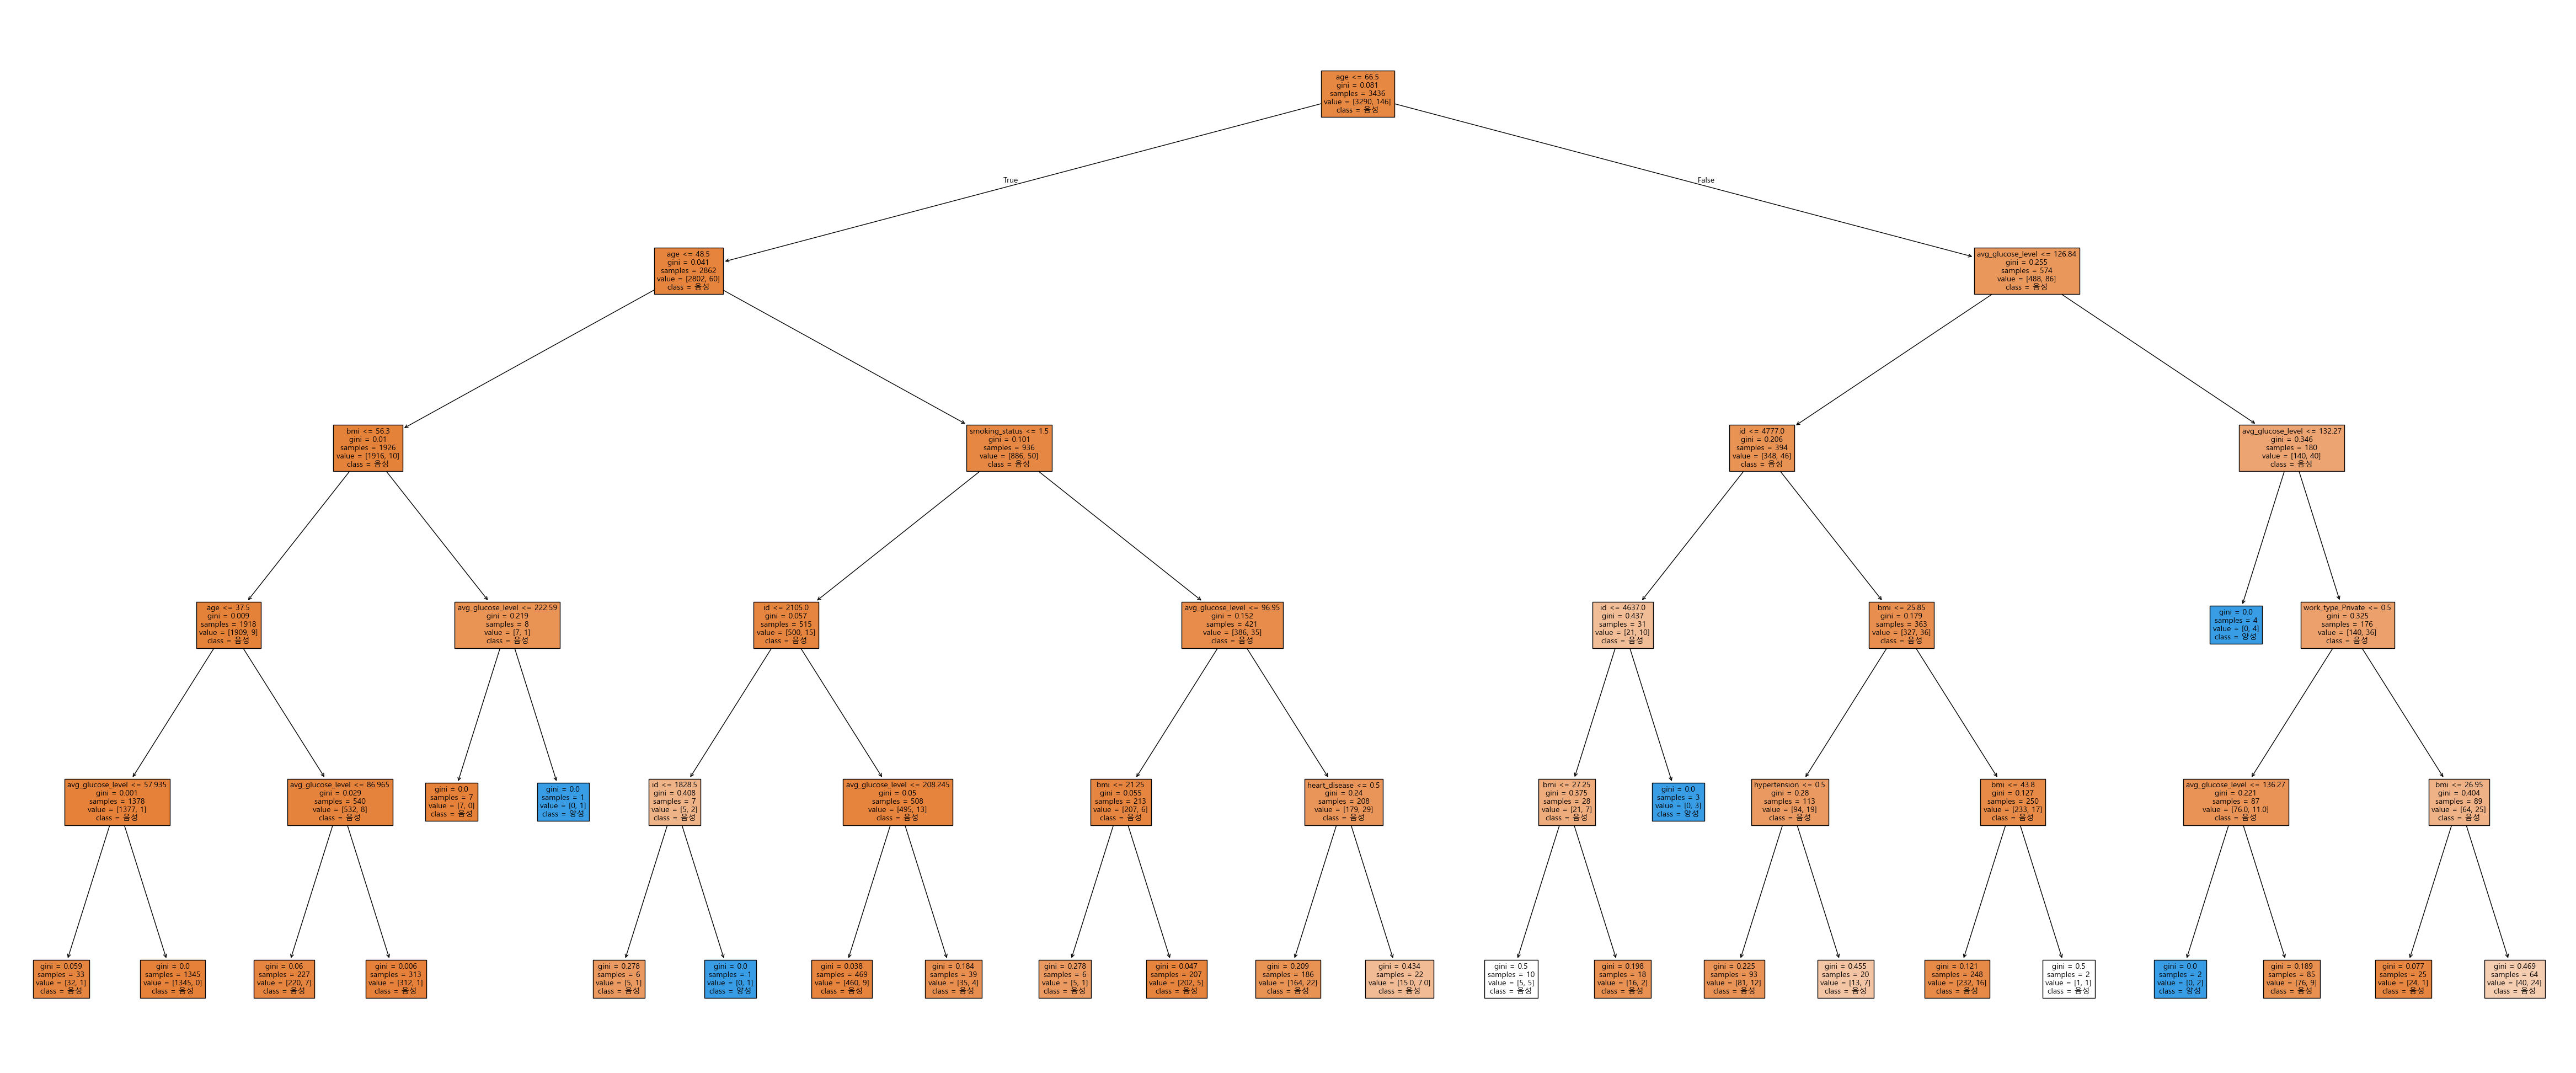

In [57]:
plt.figure(figsize=(60,25))
plot_tree(tree_md5, feature_names = X_train.columns, 
                                class_names = ['음성', '양성'], filled = True, fontsize=10)
#이미지 저장
# plt.savefig('파일 경로/ 이름', dpi = 해상도, bbox_inches='여백크기')
plt.savefig('./data/tree_md5.png', dpi = 300, bbox_inches='tight')
# 시각화 및 초기화
plt.show()

## 분류 평가 지표
- 전체 데이터에서 맞춘 개수를 기반으로 평가지표를 구할 수 있다.
- 정확도 : 전체 데이터에서 몇개를 맞췄는지
- 정밀도 : 양성(1, positive)으로 예측한 값 중 실제 몇개를 맞췄는지
- 재현율 : 실제 양성(1, positive)값 중 몇개를 예측했는지
- f1 스코어 : 정밀도와 재현율의 조화 평균

In [63]:
# 혼동행렬 불러오기
from sklearn.metrics import confusion_matrix

In [60]:
# 예측값 구하기
y_pred = tree_md5.predict(X_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(1473,))

In [61]:
y_test

3453    0
1617    0
4274    0
309     0
41      0
       ..
3814    0
1635    0
607     0
4851    0
4373    0
Name: stroke, Length: 1473, dtype: int64

In [64]:
# 혼동행렬 그리기
# confusion_matrix(실제값, 예측값)
confusion_matrix(y_test, y_pred)

array([[1404,    6],
       [  63,    0]])

In [65]:
# 분류평가지표를 리포트로 보여주는 함수(도구)
from sklearn.metrics import classification_report

In [68]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1410
           1       0.00      0.00      0.00        63

    accuracy                           0.95      1473
   macro avg       0.48      0.50      0.49      1473
weighted avg       0.92      0.95      0.93      1473



- precision : 정밀도
- recall : 재현율
- f1-score : f1스코어
- support : 클래스 데이터 개수
- accuracy : 정확도
- macro avg : 각 클래스의 결과값의 평균
- weighted avg : 각 클래스의 데이터 개수 등 가중치 반영하여 평균 낸 값